# LABS-12: Value

In this lab we will explore and observe how a model performs over different classes using our kNN model that we built in the Analytics lab. We will be using the Fairlearn package to calculate various metrics to help us understand how our model performs across different classes.

Check out their [user guide](https://fairlearn.org/v0.10/user_guide/fairness_in_machine_learning.html) for more information on the package!

In GitHub Codespaces, activate `PaulChen0508_env` in the terminal, run `pip install fairlearn` and `pip freeze > requirements.txt`, and select `PaulChen0508_env` as the notebook kernel. Run the optional installation cell only in Colab.

In [1]:
# Optional: uncomment for Colab only.
# %pip install fairlearn

In [2]:
# import packages

import pandas as pd #data ingestion & cleaning
import numpy as np #numbers

# modeling
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Fairness metrics
import fairlearn.metrics
from fairlearn.metrics import MetricFrame
from fairlearn.metrics import count, true_positive_rate, false_positive_rate, selection_rate, demographic_parity_ratio

# visualization
import matplotlib.pyplot as plt

## Recreate the model
This audit reuses the cleaned data and the selected k = 11 from the earlier Analytics lab (LABS-10 in this repository). It follows the LABS-12 split and input preparation below.

### Read in the data
The data you are reading in is the **cleaned** data that you created in LABS-9. Upload it to folders in collab if your using it.

In [3]:
from pathlib import Path

data_path = Path("results/lab10/imdb_movies_cleaned.csv")
if not data_path.is_file():
    data_path = Path("imdb_movies_cleaned.csv")
model_data = pd.read_csv(data_path)
print(f"Cleaned Analytics data: {data_path} | {len(model_data):,} movies")

Cleaned Analytics data: results/lab10/imdb_movies_cleaned.csv | 10,052 movies


Encode low scores as 0 and high scores as 1 so the positive label used by the metrics is explicit. The earlier Analytics lab used a score cutoff of 65.

In [4]:
# Recode score as 0 (low) or 1 (high).
model_data['score'] = model_data['score'].map({'low': 0, 'high': 1})
if model_data['score'].isna().any():
    raise ValueError("The cleaned data must label every movie as 'low' or 'high'.")
model_data['score'] = model_data['score'].astype(int)

### Separate features from target

In [5]:
# features: all columns except 'score'
features = model_data.drop('score', axis=1)

# Target: score column
target = model_data['score']

### Dummy variables

In [6]:
## create dummy variables for the features dataframe
features = pd.get_dummies(features)

# preview the new features dataframe
features.head()

,budget_x,revenue,year,country_AU,country_ES,country_FR,country_GB,country_HK,country_IT,country_JP,...,top_lang_Norwegian,top_lang_Polish,top_lang_Portuguese,top_lang_Russian,top_lang_Spanish,top_lang_Swedish,top_lang_Tagalog,top_lang_Thai,top_lang_Turkish,top_lang_other
0,75000000.0,2.716167e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,460000000.0,2.316795e+09,2022,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,100000000.0,7.244590e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,12300000.0,3.420000e+07,2023,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,77000000.0,3.409420e+08,2023,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Train/Test split

In [7]:
# train test split
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, random_state=45)


### Model: Build, Train, Test, and Evaluate
The earlier Analytics notebook selected k = 11. Keep that choice for this audit.

In [8]:
# Create the model
knn = KNeighborsClassifier(n_neighbors=11)  # Selected in the earlier Analytics lab.

# Train the model
knn.fit(features_train, target_train)

# Test the model
target_predicted = knn.predict(features_test)

# Evaluate the model
print("Accuracy:", accuracy_score(target_test, target_predicted))

Accuracy: 0.617105917454003


In [9]:
## Print out the data to use below
model_data.head()

,score,budget_x,revenue,country,top_genre,top_lang,year
0,1,75000000.0,2.716167e+08,AU,Drama,English,2023
1,1,460000000.0,2.316795e+09,AU,Science Fiction,English,2022
2,1,100000000.0,7.244590e+08,AU,Animation,English,2023
3,1,12300000.0,3.420000e+07,AU,Animation,Spanish,2023
4,0,77000000.0,3.409420e+08,US,Action,English,2023


## Look at the data for each category

The counts and plots use the full cleaned dataset. The later fairness metrics use the held-out test set.

country | 11 levels | 10,052 movies


,count
country,
AU,4880
US,2716
other,709
JP,502
KR,358
FR,219
GB,172
ES,151
IT,123


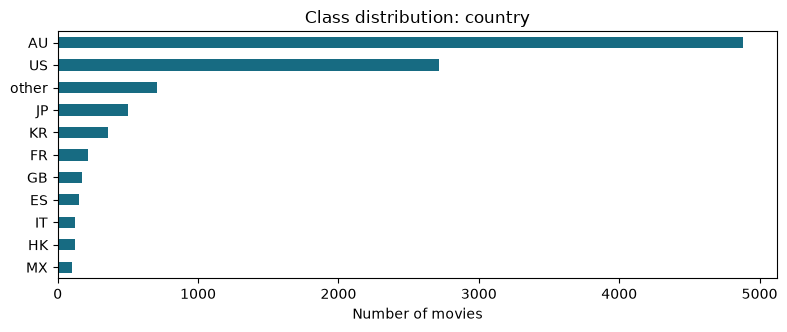

top_genre | 19 levels | 10,052 movies


,count
top_genre,
Drama,1865
Action,1563
Comedy,1377
Horror,931
Animation,885
Thriller,577
Adventure,571
Romance,413
Crime,371


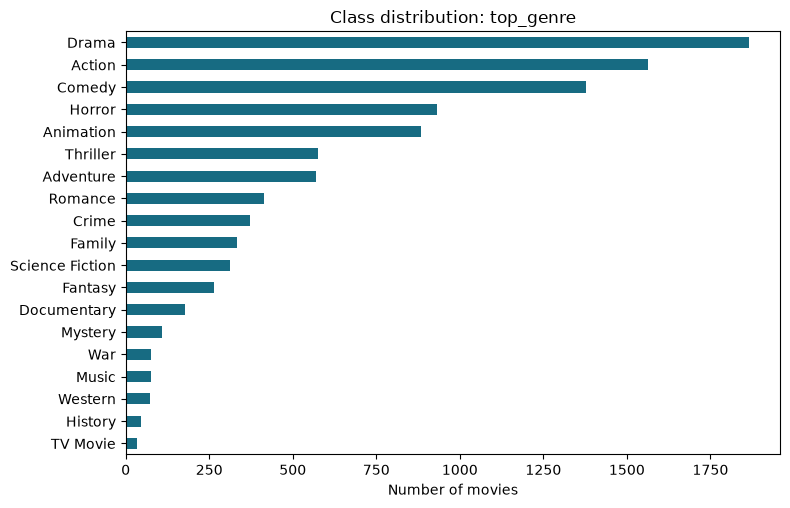

top_lang | 22 levels | 10,052 movies


,count
top_lang,
English,7381
Japanese,675
Spanish,388
Korean,384
French,282
Chinese,144
Italian,142
Cantonese,141
German,89


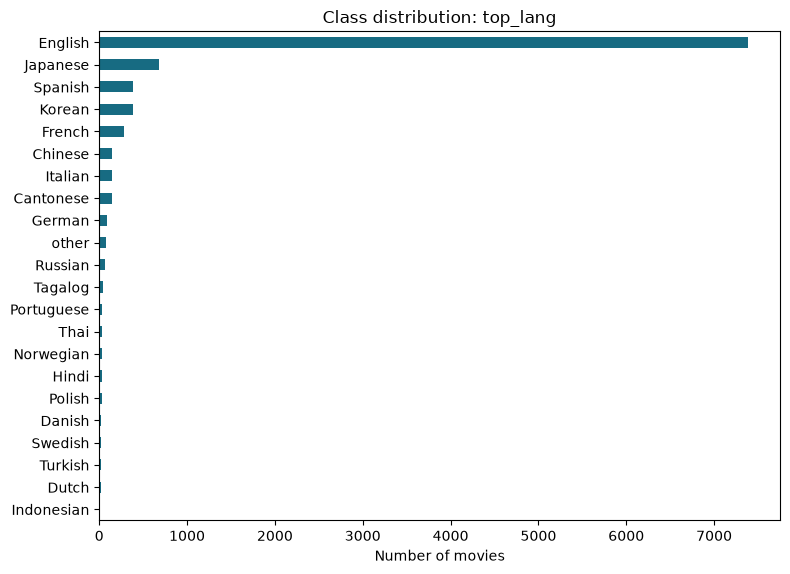

In [10]:
from IPython.display import display

categories = ("country", "top_genre", "top_lang")
for category in categories:
    counts = model_data[category].value_counts()
    print(f"{category} | {len(counts)} levels | {len(model_data):,} movies")
    display(counts.rename("count").to_frame())
    fig, ax = plt.subplots(figsize=(8, max(3, 0.22 * len(counts) + 1)))
    counts.rename(index=lambda label: str(label).strip()).sort_values().plot.barh(
        ax=ax, color="#176b82"
    )
    ax.set(xlabel="Number of movies", ylabel=None, title=f"Class distribution: {category}")
    fig.tight_layout()
    plt.show()

## Fairness Metrics

We are using the Fairlearn package in Python.

You will need to understand what the metrics used below mean and how they are calculated. You can find information on the functions used in their documentation: https://fairlearn.org/v0.10/api_reference/index.html#module-fairlearn.metrics

In [11]:
# Use the full dataset to identify the largest class, then align it to the test rows.
most_prevalent = {column: model_data[column].value_counts().idxmax()
                  for column in categories}
group_masks = {
    column: model_data.loc[features_test.index, column].eq(label)
    for column, label in most_prevalent.items()
}

my_metrics = {
    'true positive rate': true_positive_rate,
    'false positive rate': false_positive_rate,
    'selection rate': selection_rate,
    'count': count,
}
metric_frames = {
    column: MetricFrame(metrics=my_metrics, y_true=target_test, y_pred=target_predicted,
                        sensitive_features=mask)
    for column, mask in group_masks.items()
}
mf_country = metric_frames["country"]
mf_genre = metric_frames["top_genre"]
mf_lang = metric_frames["top_lang"]

In [12]:
def create_confmatrix(target_test, target_predicted):
    '''
    creates a confusion matrix with more descriptive formatting
    '''
    tn, fp, fn, tp = confusion_matrix(target_test, target_predicted, labels=[0, 1]).ravel() # grab the individual values

    # create a data frame with the values in the correct spots
    conf_matrix = pd.DataFrame({'predicted positive': [tp, fp],
                                'predicted negative': [fn, tn]},
                                index=['actual positive','actual negative'])

    # return the dataframe to be saved/viewed
    return conf_matrix

### Overall metrics

The confusion matrix shows the counts of true positives, false positives, true negatives, and false negatives across all test movies. The table below reports the three rates for the whole test set.

In [13]:
# overall confusion matrix
print("Confusion matrix for all test data:")
create_confmatrix(target_test, target_predicted)

Confusion matrix for all test data:


,predicted positive,predicted negative
actual positive,607,381
actual negative,389,634


In [14]:
## The overall metrics. You'll use these to compare to with the metrics broken down by each category below.
## Think about how the differing performance would impact that group based on your understanding of each metric.
pd.DataFrame(mf_country.overall, columns = ["overall"]).T

,true positive rate,false positive rate,selection rate,count
overall,0.614372,0.380254,0.495276,2011.0


### Metrics by category

Each comparison uses the most common class and all other classes pooled within the same category. The two parity ratios compare the groups against each other.

#### `country`

The most prevalent country value is "AU". We will compare the model performance for the most prevalent country to the performance on the rest of the countries.

In [15]:
## metrics broken down by country classes. Compare these to the metrics above.
mf_country.by_group

,true positive rate,false positive rate,selection rate,count
country,,,,
False,0.659039,0.358885,0.488625,1011.0
True,0.578947,0.407572,0.502000,1000.0


In [16]:
# Compare AU with all other values of country.
dpr_country = demographic_parity_ratio(
    target_test, target_predicted, sensitive_features=group_masks["country"]
)
eodds_country = fairlearn.metrics.equalized_odds_ratio(
    target_test, target_predicted, sensitive_features=group_masks["country"]
)
print(f"Demographic parity ratio: {dpr_country:.6f}")
print(f"Equalized odds ratio:     {eodds_country:.6f}")

Demographic parity ratio: 0.973357
Equalized odds ratio:     0.878472


#### `top_lang`


The most prevalent language value is "English". We will compare the model performance for the most prevalent language to the performance on the rest of the languages.

In [17]:
## metrics broken down by top_lang classes. Compare these to the metrics above.

mf_lang.by_group

,true positive rate,false positive rate,selection rate,count
top_lang,,,,
False,0.674576,0.319328,0.515947,533.0
True,0.588745,0.398726,0.487821,1478.0


In [18]:
# Compare English with all other values of top_lang.
dpr_lang = demographic_parity_ratio(
    target_test, target_predicted, sensitive_features=group_masks["top_lang"]
)
eodds_lang = fairlearn.metrics.equalized_odds_ratio(
    target_test, target_predicted, sensitive_features=group_masks["top_lang"]
)
print(f"Demographic parity ratio: {dpr_lang:.6f}")
print(f"Equalized odds ratio:     {eodds_lang:.6f}")

Demographic parity ratio: 0.945487
Equalized odds ratio:     0.800870


#### `top_genre`


The most prevalent genre value is "Drama". We will compare the model performance for the most prevalent genre to the performance on the rest of the genres.

In [19]:
## metrics broken down by top_genre classes. Compare these to the metrics above.

mf_genre.by_group

,true positive rate,false positive rate,selection rate,count
top_genre,,,,
False,0.612903,0.389262,0.490842,1638.0
True,0.618852,0.317829,0.514745,373.0


In [20]:
# Compare Drama with all other values of top_genre.
dpr_genre = demographic_parity_ratio(
    target_test, target_predicted, sensitive_features=group_masks["top_genre"]
)
eodds_genre = fairlearn.metrics.equalized_odds_ratio(
    target_test, target_predicted, sensitive_features=group_masks["top_genre"]
)
print(f"Demographic parity ratio: {dpr_genre:.6f}")
print(f"Equalized odds ratio:     {eodds_genre:.6f}")

Demographic parity ratio: 0.953564
Equalized odds ratio:     0.816493


### Audit summary
The summary gives the full-data representation, held-out metrics, and subgroup confusion counts used to verify the ratios.

In [21]:
overall = mf_country.overall
print(f"k = {knn.n_neighbors} | train = {len(target_train):,} | test = {len(target_test):,}")
print(f"Overall TPR {overall['true positive rate']:.3%} | FPR {overall['false positive rate']:.3%} | selection {overall['selection rate']:.3%}")
for column, frame in metric_frames.items():
    label = str(most_prevalent[column]).strip()
    size = int(model_data[column].eq(most_prevalent[column]).sum())
    print(f"\n{column}: {label} = {size:,}/{len(model_data):,} ({size/len(model_data):.2%}) in full data")
    for is_major, name in [(True, label), (False, "All others")]:
        subset = group_masks[column].eq(is_major)
        row = frame.by_group.loc[is_major]
        tn, fp, fn, tp = confusion_matrix(target_test[subset], target_predicted[subset.to_numpy()], labels=[0, 1]).ravel()
        print(f"{name:<10} n={int(row['count']):>4} | TPR {row['true positive rate']:.3%} | FPR {row['false positive rate']:.3%} | SR {row['selection rate']:.3%} | TP/FP/FN/TN={tp}/{fp}/{fn}/{tn}")
print(f"\nDPR / EOR | AU {dpr_country:.4f} / {eodds_country:.4f} | Drama {dpr_genre:.4f} / {eodds_genre:.4f} | English {dpr_lang:.4f} / {eodds_lang:.4f}")

k = 11 | train = 8,041 | test = 2,011
Overall TPR 61.437% | FPR 38.025% | selection 49.528%

country: AU = 4,880/10,052 (48.55%) in full data
AU         n=1000 | TPR 57.895% | FPR 40.757% | SR 50.200% | TP/FP/FN/TN=319/183/232/266
All others n=1011 | TPR 65.904% | FPR 35.889% | SR 48.863% | TP/FP/FN/TN=288/206/149/368

top_genre: Drama = 1,865/10,052 (18.55%) in full data
Drama      n= 373 | TPR 61.885% | FPR 31.783% | SR 51.475% | TP/FP/FN/TN=151/41/93/88
All others n=1638 | TPR 61.290% | FPR 38.926% | SR 49.084% | TP/FP/FN/TN=456/348/288/546

top_lang: English = 7,381/10,052 (73.43%) in full data
English    n=1478 | TPR 58.874% | FPR 39.873% | SR 48.782% | TP/FP/FN/TN=408/313/285/472
All others n= 533 | TPR 67.458% | FPR 31.933% | SR 51.595% | TP/FP/FN/TN=199/76/96/162

DPR / EOR | AU 0.9734 / 0.8785 | Drama 0.9536 / 0.8165 | English 0.9455 / 0.8009
